# Cleaning dan EDA: Sample Superstore

Satu pesanan bisa berisi beberapa produk. Karena itu, menghitung baris penjualan dan menghitung pesanan akan memberi hasil yang berbeda. Notebook ini menggunakan perbedaan tersebut sebagai dasar untuk membersihkan data, menggabungkan tabel, dan membaca hasil analisis.

Sumber data: **`Sample - Superstore.xls`**, dengan sheet `Orders`, `People`, dan `Returns`. Kita akan menelusuri kualitas data terlebih dahulu, lalu membahas penjualan, profit, diskon, pengiriman, dan pesanan yang tercatat di tabel retur.

## Cara menjalankan

1. Simpan notebook ini di folder yang sama dengan file Excel sumber.
2. Buka melalui Jupyter Notebook, JupyterLab, atau VS Code, lalu pilih kernel Python.
3. Jika library belum tersedia, jalankan perintah instalasi pada sel berikut.
4. Pilih **Restart Kernel and Run All** untuk menjalankan dari awal. Untuk belajar per bagian, gunakan **Shift + Enter** secara berurutan.

Jika muncul `FileNotFoundError`, periksa lokasi kerja yang ditampilkan pada bagian pembacaan data. Ubah `DATA_PATH` menjadi lokasi lengkap file Anda. Jika muncul `ModuleNotFoundError`, jalankan sel instalasi pada kernel yang sama.

Output tabel dan grafik sudah disimpan di notebook. Sel terakhir juga menyimpan data hasil cleaning dan tabel audit ke folder `output_superstore`. File sumber tetap menjadi acuan dan tidak ditulis ulang.

## Alur belajar

1. Membaca workbook dan memahami arti kolom.
2. Memeriksa nilai kosong, duplikasi, tipe data, dan aturan bisnis.
3. Menyiapkan tabel retur dan menggabungkan data dengan aman.
4. Membuat fitur analisis dan meninjau outlier.
5. Menjawab pertanyaan EDA melalui tabel dan grafik.
6. Menulis kesimpulan serta menyimpan hasil.

In [1]:
# Jalankan sekali jika library belum tersedia: hapus tanda # pada baris di bawah.
# %pip install pandas numpy matplotlib seaborn xlrd nbformat nbclient ipykernel

## 1. Menyiapkan library

`pandas` membantu membaca dan mengolah tabel. `numpy` dipakai untuk perhitungan serta pengecekan angka. Grafik dibuat dengan `matplotlib` dan `seaborn`. Library `xlrd` diperlukan untuk membaca format Excel lama, yaitu `.xls`.

Angka pada tabel menggunakan koma sebagai pemisah ribuan dan titik sebagai desimal. Pengaturan ini hanya mengubah tampilan; nilai perhitungan tetap utuh.

In [2]:
from pathlib import Path
import platform
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.0)
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110})

print(f"Python {platform.python_version()} | pandas {pd.__version__}")

Python 3.13.7 | pandas 3.0.5


## 2. Membaca semua sheet

`sheet_name=None` membaca seluruh sheet menjadi dictionary. Kita menyimpan tabel asli dengan akhiran `_raw` agar bisa membandingkannya dengan hasil cleaning.

`Orders` menyimpan baris produk dalam pesanan. `People` memetakan wilayah ke manajer. `Returns` mencatat ID pesanan dengan status retur. Tabel retur tidak menyediakan ID produk, jumlah unit yang dikembalikan, atau nilai pengembalian uang.

In [3]:
DATA_PATH = Path("Sample - Superstore.xls")
OUTPUT_DIR = DATA_PATH.resolve().parent / "output_superstore"

print("Folder kerja:", Path.cwd())
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Sample - Superstore.xls belum ditemukan. Ubah DATA_PATH ke lokasi file Anda."
    )

raw_sheets = pd.read_excel(DATA_PATH, sheet_name=None, engine="xlrd")
required_sheets = {"Orders", "People", "Returns"}
assert required_sheets.issubset(raw_sheets), "Ada sheet wajib yang tidak ditemukan."

orders_raw = raw_sheets["Orders"].copy(deep=True)
people_raw = raw_sheets["People"].copy(deep=True)
returns_raw = raw_sheets["Returns"].copy(deep=True)

sheet_overview = pd.DataFrame([
    {"sheet": name, "baris": len(table), "kolom": table.shape[1],
     "duplikat_identik": int(table.duplicated().sum())}
    for name, table in raw_sheets.items()
])
display(sheet_overview)
for name, table in raw_sheets.items():
    print(f"\nContoh isi sheet {name}:")
    display(table.head(3))

Folder kerja: F:\programming\ngajar\full_stack_bangalore\Sesi 4-5 - Python (EDA & Cleaning)


,sheet,baris,kolom,duplikat_identik
0,Orders,10194,21,0
1,People,4,2,0
2,Returns,800,2,504



Contoh isi sheet Orders:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2021-103800,2021-01-03,2021-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,0.20,5.55
1,2,US-2021-112326,2021-01-04,2021-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.54,2,0.80,-5.49
2,3,US-2021-112326,2021-01-04,2021-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.78,3,0.20,4.27



Contoh isi sheet People:


,Regional Manager,Region
0,Sadie Pawthorne,West
1,Chuck Magee,East
2,Roxanne Rodriguez,Central



Contoh isi sheet Returns:


,Returned,Order ID
0,Yes,US-2021-100762
1,Yes,US-2021-100762
2,Yes,US-2021-100762


### Memahami kolom sebelum menghitung

| Kolom sumber | Arti dan cara pakai |
| --- | --- |
| `Row ID` | Identitas satu baris produk dalam pesanan. Dipakai untuk audit baris. |
| `Order ID` | Identitas pesanan. Bisa muncul beberapa kali karena satu pesanan berisi beberapa produk. |
| `Order Date`, `Ship Date` | Tanggal pemesanan dan pengiriman dari sumber. Selisihnya bukan waktu sampai ke pelanggan. |
| `Ship Mode` | Jenis layanan pengiriman. |
| `Customer ID`, `Customer Name`, `Segment` | Identitas pelanggan dan segmennya. Nama pelanggan tidak dijadikan kunci unik. |
| `Country/Region`, `City`, `State/Province`, `Postal Code`, `Region` | Lokasi dan pembagian wilayah penjualan. Kode pos disimpan sebagai teks. |
| `Product ID`, `Product Name`, `Category`, `Sub-Category` | Identitas dan kelompok produk. |
| `Sales`, `Profit` | Nilai penjualan dan profit sebagaimana dicatat dalam sumber. Profit negatif berarti rugi. |
| `Quantity` | Jumlah unit pada satu baris. |
| `Discount` | Proporsi diskon; nilai `0.20` berarti 20%. |

File ini memuat United States dan Canada. Tidak ada kolom mata uang atau kurs. Agregasi lintas negara di notebook ini memakai **asumsi bahwa nominal sumber dapat dibandingkan** untuk latihan. Satuan grafik disebut "nominal sumber"; untuk laporan keuangan, pastikan mata uang dan kurs terlebih dahulu.

In [4]:
orders_raw.info()
display(orders_raw[["Sales", "Quantity", "Discount", "Profit"]].describe())
display(orders_raw.groupby("Country/Region").agg(
    baris=("Row ID", "size"),
    pesanan=("Order ID", "nunique"),
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
))
print("Tanggal pesanan:", orders_raw["Order Date"].min().date(),
      "sampai", orders_raw["Order Date"].max().date())

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  str           
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

,Sales,Quantity,Discount,Profit
count,"10,194.00","10,194.00","10,194.00","10,194.00"
mean,228.23,3.79,0.16,28.67
std,619.91,2.23,0.21,232.47
min,0.44,1.00,0.00,"-6,599.98"
25%,17.22,2.00,0.00,1.76
50%,53.91,3.00,0.20,8.69
75%,209.50,5.00,0.20,29.30
max,"22,638.48",14.00,0.80,"8,399.98"


,baris,pesanan,sales,profit
Country/Region,,,,
Canada,200,102,"29,333.49","5,899.79"
United States,9994,5009,"2,297,200.86","286,397.02"


Tanggal pesanan: 2021-01-03 sampai 2024-12-30


## 3. Merapikan nama kolom dan isi teks

Kita ubah nama kolom ke `snake_case`, misalnya `Order Date` menjadi `order_date`. Nama ini lebih mudah diketik saat menulis kode.

Spasi di awal dan akhir teks dihapus. Teks kosong diubah menjadi nilai hilang (`pd.NA`) agar ikut terhitung dalam audit. Kapitalisasi nama pelanggan dan produk dipertahankan. Kode pos juga tetap berupa teks karena ada kode yang mengandung huruf.

In [5]:
def normalize_table(table):
    result = table.copy(deep=True)
    result.columns = [
        re.sub(r"[^a-z0-9]+", "_", str(column).strip().lower()).strip("_")
        for column in result.columns
    ]
    assert result.columns.is_unique, "Nama kolom bertabrakan setelah normalisasi."
    for column in result.select_dtypes(include=["object", "string"]).columns:
        result[column] = result[column].astype("string").str.strip().replace("", pd.NA)
    return result

orders = normalize_table(orders_raw)
people = normalize_table(people_raw)
returns = normalize_table(returns_raw)
orders["postal_code"] = orders["postal_code"].astype("string")

column_map = pd.DataFrame({"nama_asli": orders_raw.columns, "nama_baru": orders.columns})
display(column_map)

,nama_asli,nama_baru
0,Row ID,row_id
1,Order ID,order_id
2,Order Date,order_date
3,Ship Date,ship_date
4,Ship Mode,ship_mode
5,Customer ID,customer_id
6,Customer Name,customer_name
7,Segment,segment
8,Country/Region,country_region
9,City,city


## 4. Memeriksa tipe data dan nilai kosong

Tanggal dan angka dikonversi secara eksplisit. `errors="coerce"` membuat nilai yang gagal dibaca menjadi kosong, sehingga kegagalannya bisa dihitung. Kita tidak langsung mengisinya dengan nol atau rata-rata karena itu akan mengubah makna transaksi.

Tabel `conversion_audit` menunjukkan apakah proses konversi menambah nilai kosong. Jika jumlahnya lebih dari nol, periksa sumber sebelum meneruskan analisis.

In [6]:
conversion_rows = []
for column in ["order_date", "ship_date", "sales", "quantity", "discount", "profit", "row_id"]:
    before = orders[column].copy()
    if column in ["order_date", "ship_date"]:
        orders[column] = pd.to_datetime(before, errors="coerce")
    else:
        orders[column] = pd.to_numeric(before, errors="coerce")
    conversion_rows.append({
        "kolom": column,
        "gagal_konversi": int((before.notna() & orders[column].isna()).sum()),
    })

conversion_audit = pd.DataFrame(conversion_rows)
quality_profile = pd.DataFrame({
    "tipe_data": orders.dtypes.astype(str),
    "nilai_kosong": orders.isna().sum(),
    "persen_kosong": orders.isna().mean() * 100,
    "nilai_unik": orders.nunique(dropna=True),
})
display(conversion_audit)
display(quality_profile)
display(pd.DataFrame({name: table.isna().sum() for name, table in
                      {"People": people, "Returns": returns}.items()}).fillna("tidak ada kolom"))
assert conversion_audit["gagal_konversi"].sum() == 0, "Periksa nilai yang gagal dikonversi."

,kolom,gagal_konversi
0,order_date,0
1,ship_date,0
2,sales,0
3,quantity,0
4,discount,0
5,profit,0
6,row_id,0


,tipe_data,nilai_kosong,persen_kosong,nilai_unik
row_id,int64,0,0.00,10194
order_id,string,0,0.00,5111
order_date,datetime64[us],0,0.00,1242
ship_date,datetime64[us],0,0.00,1338
ship_mode,string,0,0.00,4
customer_id,string,0,0.00,804
customer_name,string,0,0.00,800
segment,string,0,0.00,3
country_region,string,0,0.00,2
city,string,0,0.00,542


,People,Returns
order_id,tidak ada kolom,0.00
region,0.00,tidak ada kolom
regional_manager,0.00,tidak ada kolom
returned,tidak ada kolom,0.00


### Keputusan tentang nilai kosong

Pada file yang diperiksa, seluruh kolom sumber terisi. Karena itu, kita tidak melakukan imputasi. Ini tetap merupakan hasil cleaning yang sah: pemeriksaan dapat menunjukkan bahwa suatu perbaikan tidak diperlukan.

Jika file Anda berubah, tabel audit di atas perlu dibaca ulang. Nilai penjualan yang hilang memerlukan penelusuran transaksi; mengisinya dengan nol akan menurunkan total penjualan secara tidak berdasar.

## 5. Membedakan duplikasi dan baris yang mirip

Duplikat identik mencakup semua kolom, termasuk `row_id`. Sementara itu, dua baris dengan isi transaksi sama tetapi `row_id` berbeda masih perlu ditinjau. Keduanya bisa merupakan pencatatan ganda atau dua baris yang memang sah.

Kita menghapus salinan yang identik penuh, lalu mempertahankan baris dengan ID berbeda sambil memberi tanda untuk audit. `order_id` yang berulang tidak dihapus karena satu pesanan dapat berisi banyak produk.

In [7]:
rows_before = len(orders)
exact_duplicate_count = int(orders.duplicated().sum())
orders = orders.drop_duplicates().copy()

business_columns = orders.columns.drop("row_id").tolist()
orders["flag_similar_transaction"] = orders.duplicated(subset=business_columns, keep=False)
similar_transactions = orders.loc[orders["flag_similar_transaction"]].copy()

print("Duplikat identik yang dihapus:", exact_duplicate_count)
print("Row ID berulang:", int(orders["row_id"].duplicated().sum()))
print("Baris yang termasuk kelompok transaksi mirip:", len(similar_transactions))
display(similar_transactions)
assert orders["row_id"].notna().all() and orders["row_id"].is_unique, "Periksa identitas baris."

Duplikat identik yang dihapus: 0
Row ID berulang: 0
Baris yang termasuk kelompok transaksi mirip: 4


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country_region,city,state_province,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,flag_similar_transaction
390,391,US-2021-150119,2021-04-23,2021-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.37,2,0.30,-12.06,True
391,392,US-2021-150119,2021-04-23,2021-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.37,2,0.30,-12.06,True
1698,1699,CA-2021-153623,2021-11-24,2021-12-05,Standard Class,JP-11135,James Peterman,Corporate,Canada,St. John's,Newfoundland and Labrador,A0A,East,FUR-FU-10002501,Furniture,Furnishings,Nu-Dell Executive Frame,99.12,8,0.00,35.41,True
1699,1700,CA-2021-153623,2021-11-24,2021-12-05,Standard Class,JP-11135,James Peterman,Corporate,Canada,St. John's,Newfoundland and Labrador,A0A,East,FUR-FU-10002501,Furniture,Furnishings,Nu-Dell Executive Frame,99.12,8,0.00,35.41,True


## 6. Memeriksa aturan bisnis dan identitas pelanggan

Penjualan harus bernilai positif pada dataset penjualan ini, kuantitas harus berupa bilangan bulat positif, diskon berada di antara 0 dan 1, dan tanggal pengiriman tidak boleh mendahului pesanan. Profit boleh negatif.

Kita juga memeriksa apakah satu ID pesanan terhubung ke lebih dari satu ID pelanggan. Jika ditemukan, data diberi tanda. Mengganti ID hanya berdasarkan nama pelanggan dapat menyatukan pelanggan yang sebenarnya berbeda.

In [8]:
numeric_columns = ["sales", "quantity", "discount", "profit"]
checks = pd.Series({
    "nilai wajib kosong": int(orders.drop(columns="flag_similar_transaction").isna().any(axis=1).sum()),
    "angka tidak finite": int((~np.isfinite(orders[numeric_columns])).any(axis=1).sum()),
    "sales nol atau negatif": int(orders["sales"].le(0).sum()),
    "quantity tidak valid": int((orders["quantity"].le(0) | orders["quantity"].mod(1).ne(0)).sum()),
    "discount di luar 0 sampai 1": int((~orders["discount"].between(0, 1)).sum()),
    "ship_date sebelum order_date": int(orders["ship_date"].lt(orders["order_date"]).sum()),
}, name="jumlah_baris")
display(checks.to_frame())
assert checks.eq(0).all(), "Ada nilai tidak valid. Tinjau sumber sebelum melanjutkan."

customer_counts = orders.groupby("order_id")["customer_id"].nunique()
conflicting_order_ids = customer_counts[customer_counts.gt(1)].index
orders["flag_customer_conflict"] = orders["order_id"].isin(conflicting_order_ids)
customer_conflicts = orders.loc[orders["flag_customer_conflict"], [
    "row_id", "order_id", "customer_id", "customer_name", "country_region", "sales"
]].copy()
print("Pesanan dengan lebih dari satu ID pelanggan:", len(conflicting_order_ids))
display(customer_conflicts)

# Kolom ini perlu konsisten sebelum diringkas menjadi satu baris per pesanan.
order_attributes = ["order_date", "ship_date", "ship_mode", "region", "country_region", "segment"]
attribute_counts = orders.groupby("order_id")[order_attributes].nunique()
assert attribute_counts.le(1).all().all(), "Atribut pesanan tidak konsisten; tinjau sebelum agregasi."

,jumlah_baris
nilai wajib kosong,0
angka tidak finite,0
sales nol atau negatif,0
quantity tidak valid,0
discount di luar 0 sampai 1,0
ship_date sebelum order_date,0


Pesanan dengan lebih dari satu ID pelanggan: 2


,row_id,order_id,customer_id,customer_name,country_region,sales
5009,5010,CA-2023-121465,HO-15234,Harry Olson,Canada,140.67
5010,5011,CA-2023-121465,HO-15233,Harry Olson,Canada,19.68
5011,5012,CA-2023-121465,HO-15232,Harry Olson,Canada,70.46
5012,5013,CA-2023-121465,HO-15231,Harry Olson,Canada,310.12
7191,7192,CA-2024-130494,HO-15234,Harry Olson,Canada,140.67
7192,7193,CA-2024-130494,HO-15233,Harry Olson,Canada,19.68
7193,7194,CA-2024-130494,HO-15232,Harry Olson,Canada,70.46
7194,7195,CA-2024-130494,HO-15231,Harry Olson,Canada,310.12


Pada sumber ini, ada dua pesanan dengan beberapa ID pelanggan untuk nama yang sama. ID asli dipertahankan dan baris terkait disimpan dalam `customer_conflicts`. Jumlah pelanggan unik nantinya berarti jumlah **ID yang tercatat**, bukan jumlah orang yang sudah tervalidasi.

## 7. Menyiapkan tabel retur dan manajer

`Returns` berisi 800 baris untuk 296 ID pesanan unik pada file ini. Karena tabel hanya menyediakan ID pesanan dan status, kita menyiapkannya menjadi satu baris per pesanan untuk kebutuhan penandaan retur. Pengulangan tersebut tidak bisa ditafsirkan sebagai jumlah kejadian atau unit yang diretur.

Sebelum penggabungan, status yang tidak dikenal dan konflik status akan menghentikan proses. Pemetaan manajer juga harus mempunyai satu baris per wilayah.

In [9]:
returns["returned"] = returns["returned"].str.casefold()
assert returns[["order_id", "returned"]].notna().all().all(), "Kunci atau status retur kosong."
assert returns["returned"].isin(["yes", "no"]).all(), "Ada status retur yang belum dipetakan."
assert returns.groupby("order_id")["returned"].nunique().le(1).all(), "Status retur bertentangan."

returns_lookup = returns.drop_duplicates(subset="order_id").copy()
returns_lookup["is_returned_order"] = returns_lookup["returned"].eq("yes")
returns_lookup = returns_lookup[["order_id", "is_returned_order"]]

people_lookup = people.drop_duplicates().copy()
assert people_lookup.notna().all().all(), "Pemetaan manajer memiliki nilai kosong."
assert people_lookup["region"].is_unique, "Ada lebih dari satu manajer untuk wilayah yang sama."

unmatched_returns = returns_lookup.loc[~returns_lookup["order_id"].isin(orders["order_id"])].copy()
print("Baris retur sumber:", len(returns))
print("Pesanan pada lookup retur:", len(returns_lookup))
print("Baris pengulangan yang diringkas:", len(returns) - len(returns_lookup))
print("ID retur tanpa pasangan di Orders:", len(unmatched_returns))
display(people_lookup)
display(unmatched_returns)

Baris retur sumber: 800
Pesanan pada lookup retur: 296
Baris pengulangan yang diringkas: 504
ID retur tanpa pasangan di Orders: 0


,regional_manager,region
0,Sadie Pawthorne,West
1,Chuck Magee,East
2,Roxanne Rodriguez,Central
3,Fred Suzuki,South


,order_id,is_returned_order


### Menggabungkan tanpa menggandakan penjualan

`how="left"` mempertahankan semua baris penjualan. `validate="many_to_one"` meminta pandas memastikan bahwa setiap kunci di tabel lookup hanya memiliki satu pasangan. Setelah digabung, jumlah baris, total sales, dan total profit harus tetap sama.

Pesanan yang tidak ditemukan di tabel retur diberi nilai `False`. Artinya **tidak tercatat sebagai retur dalam file ini**. Kita belum mengetahui kelengkapan pencatatan retur. Status ini berlaku pada tingkat pesanan; tidak membuktikan bahwa semua produk di pesanan tersebut dikembalikan.

In [10]:
baseline_totals = orders[["sales", "profit", "quantity"]].sum()
clean = orders.merge(people_lookup, on="region", how="left", validate="many_to_one")
clean = clean.merge(returns_lookup, on="order_id", how="left", validate="many_to_one")
clean["is_returned_order"] = clean["is_returned_order"].astype("boolean").fillna(False).astype(bool)

assert len(clean) == len(orders), "Jumlah baris berubah saat join."
assert clean["regional_manager"].notna().all(), "Ada wilayah yang belum terpetakan."
np.testing.assert_allclose(clean[["sales", "profit", "quantity"]].sum(), baseline_totals)
print(f"Join terverifikasi: {len(clean):,} baris; total sales, profit, dan quantity tetap.")

Join terverifikasi: 10,194 baris; total sales, profit, dan quantity tetap.


## 8. Membuat kolom untuk analisis

`shipping_days` adalah selisih hari dari tanggal pesanan ke tanggal pengiriman. `profit_margin_pct` menghitung margin per baris. Untuk margin suatu kelompok, kita akan memakai **total profit / total sales × 100**, karena rata-rata margin baris memberi bobot yang sama kepada transaksi kecil dan besar.

`sales_per_unit` dihitung dari sales dibagi quantity. Ini adalah nominal penjualan per unit yang tercatat; sumber tidak menyediakan harga katalog atau rincian biaya.

In [11]:
clean["order_year"] = clean["order_date"].dt.year
clean["order_month"] = clean["order_date"].dt.to_period("M").dt.to_timestamp()
clean["shipping_days"] = (clean["ship_date"] - clean["order_date"]).dt.days
clean["profit_margin_pct"] = clean["profit"] / clean["sales"] * 100
clean["sales_per_unit"] = clean["sales"] / clean["quantity"]
clean["is_loss"] = clean["profit"].lt(0)
display(clean[["row_id", "order_id", "sales", "profit", "profit_margin_pct",
               "shipping_days", "is_returned_order"]].head())

,row_id,order_id,sales,profit,profit_margin_pct,shipping_days,is_returned_order
0,1,US-2021-103800,16.45,5.55,33.75,4,False
1,2,US-2021-112326,3.54,-5.49,-155.00,4,False
2,3,US-2021-112326,11.78,4.27,36.25,4,False
3,4,US-2021-112326,272.74,-64.77,-23.75,4,False
4,5,US-2021-141817,19.54,4.88,25.00,7,False


## 9. Meninjau outlier tanpa membuang transaksi

IQR adalah jarak antara kuartil pertama (Q1) dan kuartil ketiga (Q3). Nilai di luar batas `Q1 - 1.5 × IQR` sampai `Q3 + 1.5 × IQR` ditandai untuk ditinjau.

Penjualan ritel sering memiliki banyak transaksi kecil dan sedikit transaksi besar. Karena itu, tanda outlier belum cukup untuk menyatakan bahwa suatu nilai salah. Semua transaksi tetap masuk ke EDA, termasuk transaksi rugi. Tabel berikut memperlihatkan seberapa besar bagian sales yang berasal dari baris yang ditandai.

,kolom,batas_bawah,batas_atas,baris_ditandai,persen_baris
0,sales,-271.20,497.92,1183,11.60
1,profit,-39.54,70.60,1913,18.77


Baris dengan outlier sales menyumbang 64.20% dari total sales.


,row_id,product_name,sales,profit,discount
226,227,Cisco TelePresence System EX90 Videoconferenci...,"22,638.48","-1,811.08",0.50
5894,5895,Canon imageCLASS 2200 Advanced Copier,"17,499.95","8,399.98",0.00
7255,7256,Canon imageCLASS 2200 Advanced Copier,"13,999.96","6,719.98",0.00
9171,9172,Canon imageCLASS 2200 Advanced Copier,"11,199.97","3,919.99",0.20
9517,9518,Canon imageCLASS 2200 Advanced Copier,"10,499.97","5,039.99",0.00


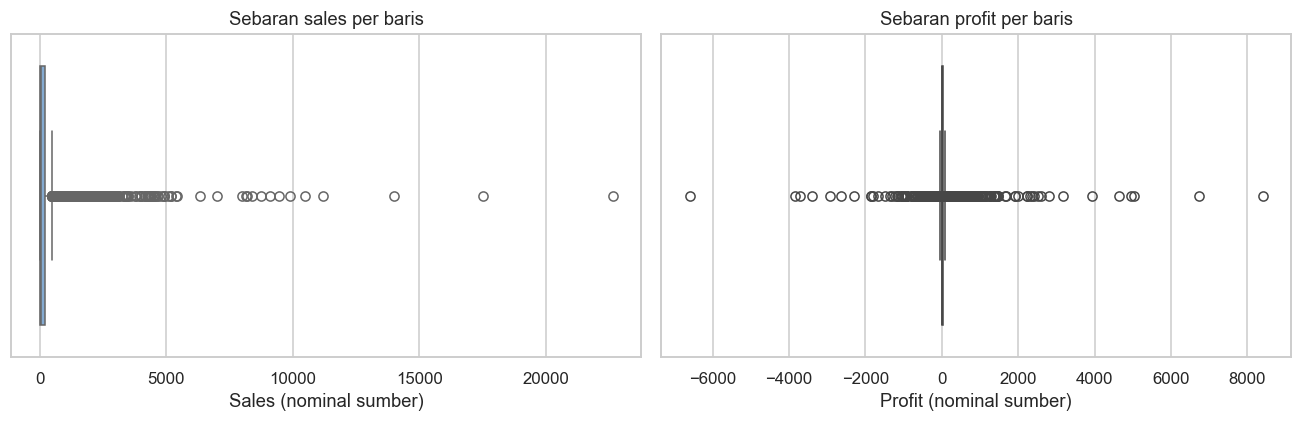

In [12]:
outlier_rows = []
for column in ["sales", "profit"]:
    q1, q3 = clean[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flag_column = f"flag_outlier_{column}"
    clean[flag_column] = ~clean[column].between(lower, upper)
    outlier_rows.append({"kolom": column, "batas_bawah": lower, "batas_atas": upper,
                         "baris_ditandai": int(clean[flag_column].sum()),
                         "persen_baris": clean[flag_column].mean() * 100})
outlier_audit = pd.DataFrame(outlier_rows)
display(outlier_audit)
outlier_sales_share = clean.loc[clean["flag_outlier_sales"], "sales"].sum() / clean["sales"].sum() * 100
print(f"Baris dengan outlier sales menyumbang {outlier_sales_share:.2f}% dari total sales.")
display(clean.nlargest(5, "sales")[["row_id", "product_name", "sales", "profit", "discount"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=clean, x="sales", ax=axes[0], color="#77AADD")
sns.boxplot(data=clean, x="profit", ax=axes[1], color="#44AA99")
axes[0].set(title="Sebaran sales per baris", xlabel="Sales (nominal sumber)")
axes[1].set(title="Sebaran profit per baris", xlabel="Profit (nominal sumber)")
plt.tight_layout()
plt.show()

### Catatan hasil cleaning

Tabel ini merangkum tindakan yang benar-benar dilakukan. Baris bertanda konflik pelanggan, transaksi mirip, dan outlier tetap disimpan agar bisa ditelusuri kembali melalui `row_id`.

In [13]:
cleaning_log = pd.DataFrame([
    {"pemeriksaan": "Baris Orders awal", "jumlah": rows_before, "tindakan": "Simpan sumber asli"},
    {"pemeriksaan": "Duplikat identik Orders", "jumlah": exact_duplicate_count, "tindakan": "Hapus salinan identik jika ada"},
    {"pemeriksaan": "Nilai kosong Orders", "jumlah": int(quality_profile["nilai_kosong"].sum()), "tindakan": "Tidak melakukan imputasi"},
    {"pemeriksaan": "Baris transaksi mirip", "jumlah": len(similar_transactions), "tindakan": "Pertahankan dan tandai"},
    {"pemeriksaan": "Pesanan dengan konflik pelanggan", "jumlah": len(conflicting_order_ids), "tindakan": "Pertahankan ID asli dan tandai"},
    {"pemeriksaan": "Pengulangan pada lookup Returns", "jumlah": len(returns) - len(returns_lookup), "tindakan": "Ringkas satu baris per order_id"},
    {"pemeriksaan": "Baris setelah join", "jumlah": len(clean), "tindakan": "Cocokkan jumlah dan total dengan sebelum join"},
])
display(cleaning_log)

,pemeriksaan,jumlah,tindakan
0,Baris Orders awal,10194,Simpan sumber asli
1,Duplikat identik Orders,0,Hapus salinan identik jika ada
2,Nilai kosong Orders,0,Tidak melakukan imputasi
3,Baris transaksi mirip,4,Pertahankan dan tandai
4,Pesanan dengan konflik pelanggan,2,Pertahankan ID asli dan tandai
5,Pengulangan pada lookup Returns,504,Ringkas satu baris per order_id
6,Baris setelah join,10194,Cocokkan jumlah dan total dengan sebelum join


## 10. Gambaran umum penjualan

Kita hitung pesanan dengan `nunique()`. Rata-rata nilai pesanan (AOV) adalah total sales dibagi jumlah ID pesanan unik. Persentase baris rugi menggunakan seluruh baris produk sebagai penyebut. Persentase pesanan tercatat retur menggunakan seluruh pesanan sebagai penyebut.

Data `order_level` mempunyai satu baris per pesanan. Kolom tanggal, wilayah, segmen, dan pengiriman sudah diperiksa konsistensinya sebelum diambil dengan `first`.

In [14]:
order_level = clean.groupby("order_id", as_index=False).agg(
    order_date=("order_date", "first"),
    ship_mode=("ship_mode", "first"),
    shipping_days=("shipping_days", "first"),
    region=("region", "first"),
    country_region=("country_region", "first"),
    segment=("segment", "first"),
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    quantity=("quantity", "sum"),
    is_returned_order=("is_returned_order", "max"),
)
total_sales = clean["sales"].sum()
total_profit = clean["profit"].sum()
overall_margin = total_profit / total_sales * 100
recorded_return_rate = order_level["is_returned_order"].mean() * 100

kpi = pd.DataFrame([
    ("Baris produk", len(clean), "baris"),
    ("Pesanan unik", len(order_level), "order_id"),
    ("ID pelanggan tercatat", clean["customer_id"].nunique(), "customer_id; ada konflik identitas"),
    ("Unit terjual", clean["quantity"].sum(), "unit"),
    ("Total sales", total_sales, "nominal sumber"),
    ("Total profit", total_profit, "nominal sumber"),
    ("Margin keseluruhan", overall_margin, "%"),
    ("Rata-rata nilai pesanan", total_sales / len(order_level), "nominal sumber per pesanan"),
    ("Baris dengan profit negatif", clean["is_loss"].mean() * 100, "% baris"),
    ("Pesanan tercatat retur", recorded_return_rate, "% pesanan"),
], columns=["metrik", "nilai", "satuan"])
display(kpi)

,metrik,nilai,satuan
0,Baris produk,"10,194.00",baris
1,Pesanan unik,"5,111.00",order_id
2,ID pelanggan tercatat,804.00,customer_id; ada konflik identitas
3,Unit terjual,"38,654.00",unit
4,Total sales,"2,326,534.35",nominal sumber
5,Total profit,"292,296.81",nominal sumber
6,Margin keseluruhan,12.56,%
7,Rata-rata nilai pesanan,455.20,nominal sumber per pesanan
8,Baris dengan profit negatif,18.65,% baris
9,Pesanan tercatat retur,5.79,% pesanan


## 11. Seperti apa distribusi penjualannya?

Histogram pertama menunjukkan sales per baris pada skala asli. Grafik kedua memakai `log1p(sales)` agar transaksi kecil lebih terlihat. Transformasi ini hanya dipakai untuk visualisasi; total penjualan tetap dihitung dari nilai asli.

Bandingkan rata-rata dan median pada output. Selisih yang besar menunjukkan bahwa transaksi bernilai tinggi menarik rata-rata ke atas.

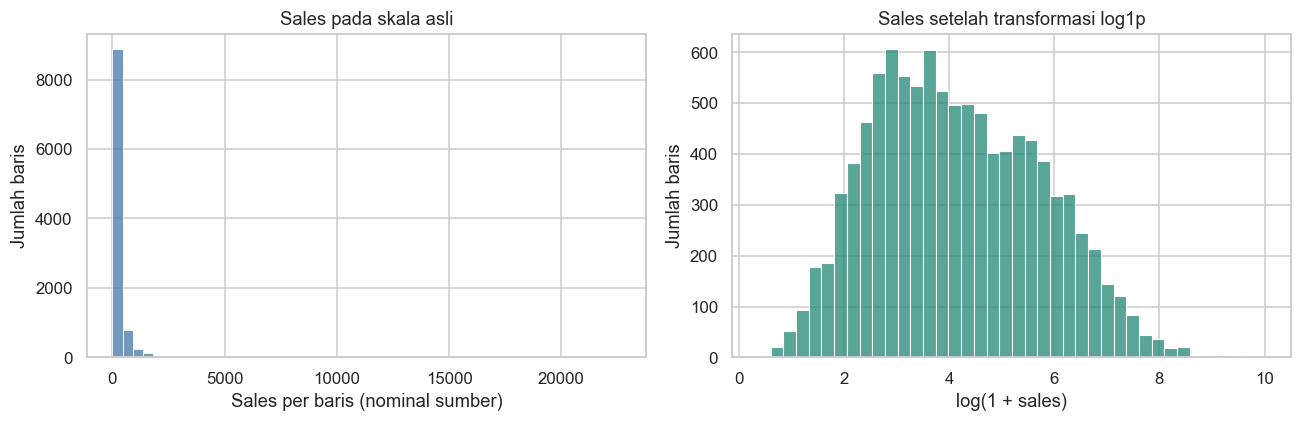

Rata-rata sales per baris: 228.23
Median sales per baris: 53.91


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=clean, x="sales", bins=50, ax=axes[0], color="#4477AA")
sns.histplot(x=np.log1p(clean["sales"]), bins=40, ax=axes[1], color="#228877")
axes[0].set(title="Sales pada skala asli", xlabel="Sales per baris (nominal sumber)", ylabel="Jumlah baris")
axes[1].set(title="Sales setelah transformasi log1p", xlabel="log(1 + sales)", ylabel="Jumlah baris")
plt.tight_layout()
plt.show()
print(f"Rata-rata sales per baris: {clean['sales'].mean():,.2f}")
print(f"Median sales per baris: {clean['sales'].median():,.2f}")

## 12. Bagaimana perubahan sales dan profit dari waktu ke waktu?

Agregasi bulanan memakai tanggal pesanan. Bulan yang tidak memiliki catatan ditampilkan sebagai celah, karena kita belum bisa memastikan apakah itu berarti nol penjualan atau data yang tidak tersedia.

Persentase perubahan tahunan membandingkan total dengan tahun sebelumnya. Periksa rentang tanggal dan cakupan bulan sebelum membandingkan periode. Pola bulanan dapat menjadi bahan dugaan tentang musim penjualan, tetapi EDA ini belum menguji penyebabnya.

,sales,profit,pesanan,bulan_tercatat,tanggal_awal,tanggal_akhir,pertumbuhan_sales_pct,margin_pct
order_year,,,,,,,,
2021,"494,040.21","51,684.30",995,12,2021-01-03,2021-12-31,NaN,10.46
2022,"472,993.03","62,020.97",1053,12,2022-01-02,2022-12-31,-4.26,13.11
2023,"613,933.58","82,665.20",1340,12,2023-01-02,2023-12-31,29.80,13.46
2024,"745,567.53","95,926.35",1723,12,2024-01-01,2024-12-30,21.44,12.87


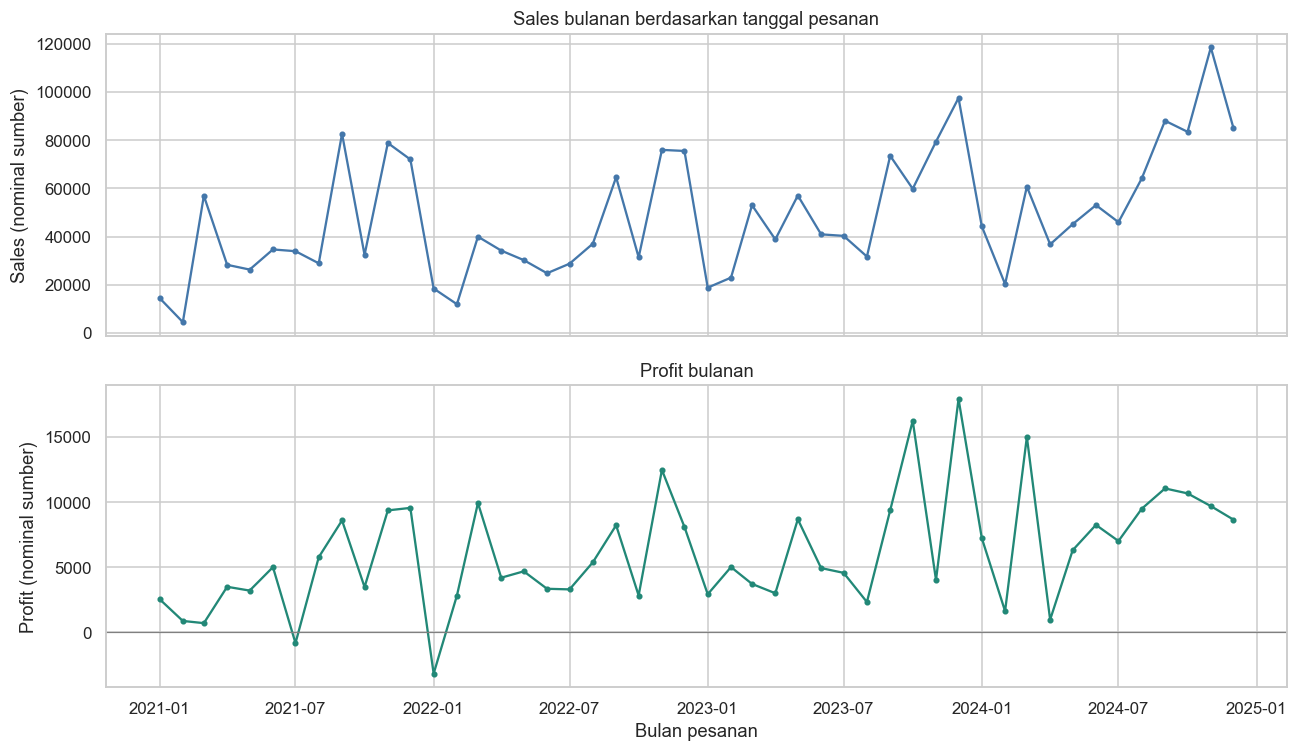

In [16]:
monthly = clean.groupby("order_month")[["sales", "profit"]].sum()
calendar = pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS")
monthly = monthly.reindex(calendar).rename_axis("order_month")

annual = clean.groupby("order_year").agg(
    sales=("sales", "sum"), profit=("profit", "sum"),
    pesanan=("order_id", "nunique"), bulan_tercatat=("order_month", "nunique"),
    tanggal_awal=("order_date", "min"), tanggal_akhir=("order_date", "max"),
)
annual["pertumbuhan_sales_pct"] = annual["sales"].pct_change(fill_method=None) * 100
annual["margin_pct"] = annual["profit"] / annual["sales"] * 100
display(annual)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(monthly.index, monthly["sales"], marker="o", markersize=3, color="#4477AA")
axes[1].plot(monthly.index, monthly["profit"], marker="o", markersize=3, color="#228877")
axes[0].set(title="Sales bulanan berdasarkan tanggal pesanan", ylabel="Sales (nominal sumber)")
axes[1].set(title="Profit bulanan", ylabel="Profit (nominal sumber)", xlabel="Bulan pesanan")
axes[1].axhline(0, color="gray", linewidth=0.8)
plt.tight_layout()
plt.show()

## 13. Kategori mana yang menghasilkan sales dan profit terbesar?

Fungsi `summarize_sales()` mengumpulkan metrik yang sama untuk beberapa kelompok. `size` menghitung baris, `nunique` menghitung pesanan unik, dan `sum` menjumlahkan nominal. Jumlah pesanan per kategori tidak boleh dijumlahkan menjadi total pesanan karena satu pesanan bisa memuat beberapa kategori.

Perhatikan margin di samping sales. Kategori dengan sales besar belum tentu menghasilkan margin terbesar.

,baris,pesanan,sales,profit,unit,baris_rugi,margin_pct,baris_rugi_pct
category,,,,,,,,
Technology,1865,1560,"839,893.28","146,543.38",7017,271,17.45,14.53
Furniture,2201,1819,"754,747.76","19,730.00",8369,732,2.61,33.26
Office Supplies,6128,3812,"731,893.31","126,023.44",23268,898,17.22,14.65


,baris,pesanan,sales,profit,unit,baris_rugi,margin_pct,baris_rugi_pct
sub_category,,,,,,,,
Tables,326,314,"208,020.18","-17,753.21",1261,205,-8.53,62.88
Bookcases,232,228,"115,361.20","-3,632.07",878,111,-3.15,47.84
Supplies,192,189,"46,725.50","-1,171.39",653,33,-2.51,17.19
Fasteners,229,226,"8,532.24","2,428.64",980,12,28.46,5.24
Machines,117,114,"189,925.03","3,461.98",442,44,1.82,37.61
Labels,368,348,"12,695.04","5,572.78",1410,2,43.90,0.54
Art,821,756,"27,659.01","6,653.20",3092,1,24.05,0.12


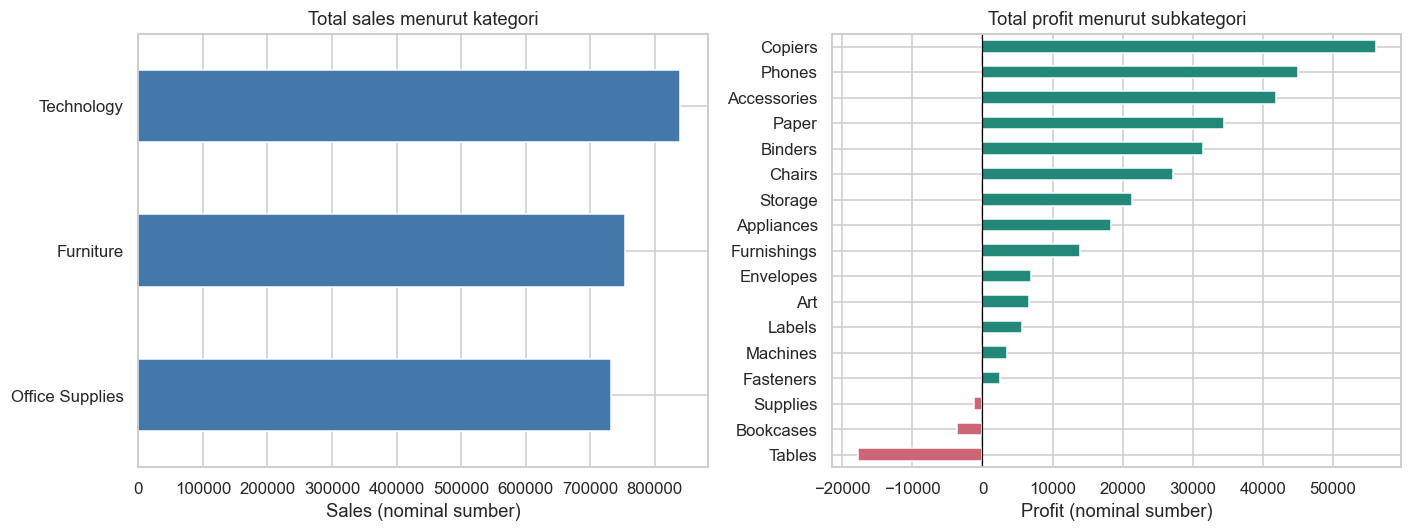

In [17]:
def summarize_sales(data, by):
    summary = data.groupby(by, observed=True, dropna=False).agg(
        baris=("row_id", "size"),
        pesanan=("order_id", "nunique"),
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        unit=("quantity", "sum"),
        baris_rugi=("is_loss", "sum"),
    )
    summary["margin_pct"] = summary["profit"] / summary["sales"] * 100
    summary["baris_rugi_pct"] = summary["baris_rugi"] / summary["baris"] * 100
    return summary.sort_values("sales", ascending=False)

category_summary = summarize_sales(clean, "category")
subcategory_summary = summarize_sales(clean, "sub_category")
display(category_summary)
display(subcategory_summary.sort_values("profit").head(7))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
category_summary["sales"].sort_values().plot.barh(ax=axes[0], color="#4477AA")
sub_profit = subcategory_summary["profit"].sort_values()
sub_profit.plot.barh(ax=axes[1], color=["#CC6677" if value < 0 else "#228877" for value in sub_profit])
axes[0].set(title="Total sales menurut kategori", xlabel="Sales (nominal sumber)", ylabel="")
axes[1].set(title="Total profit menurut subkategori", xlabel="Profit (nominal sumber)", ylabel="")
axes[1].axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

## 14. Bagaimana perbedaan wilayah, negara, dan segmen?

Ringkasan wilayah dan segmen membantu menemukan kelompok yang perlu diperiksa lebih jauh. Tabel negara disajikan terpisah karena jumlah baris United States dan Canada tidak seimbang.

Wilayah dengan profit lebih tinggi mungkin memiliki volume, produk, dan komposisi pelanggan yang berbeda. Perbandingan ini belum mengukur kinerja individual manajer.

,baris,pesanan,sales,profit,unit,baris_rugi,margin_pct,baris_rugi_pct
region,,,,,,,,
West,3253,1635,"739,813.61","110,798.82",12466,321,14.98,9.87
East,2986,1475,"691,828.17","94,883.26",11159,574,13.71,19.22
Central,2335,1179,"503,170.67","39,865.31",8820,747,7.92,31.99
South,1620,822,"391,721.91","46,749.43",6209,259,11.93,15.99


,baris,pesanan,sales,profit,unit,baris_rugi,margin_pct,baris_rugi_pct
segment,,,,,,,,
Consumer,5281,2628,"1,170,659.79","136,371.45",19844,1018,11.65,19.28
Corporate,3090,1552,"715,806.13","94,249.64",11898,562,13.17,18.19
Home Office,1823,931,"440,068.43","61,675.73",6912,321,14.02,17.61


,baris,pesanan,sales,profit,unit,baris_rugi,margin_pct,baris_rugi_pct
country_region,,,,,,,,
United States,9994,5009,"2,297,200.86","286,397.02",37873,1871,12.47,18.72
Canada,200,102,"29,333.49","5,899.79",781,30,20.11,15.00


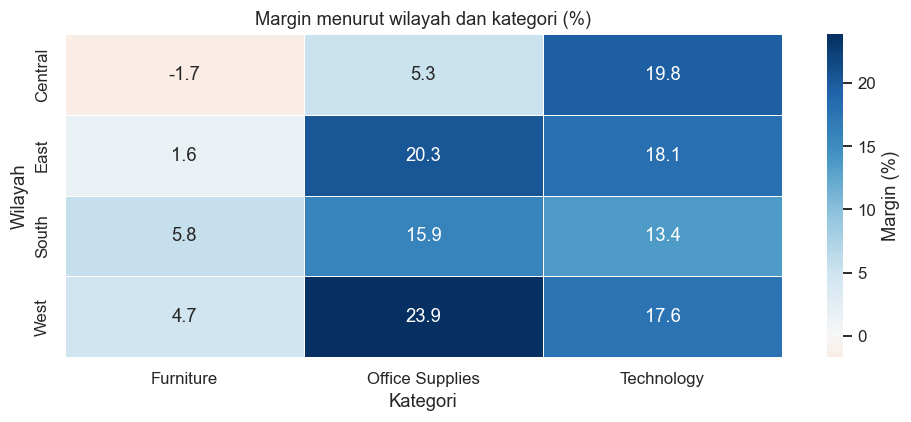

In [18]:
region_summary = summarize_sales(clean, "region")
segment_summary = summarize_sales(clean, "segment")
country_summary = summarize_sales(clean, "country_region")
display(region_summary)
display(segment_summary)
display(country_summary)

region_category_margin = (
    clean.pivot_table(index="region", columns="category", values="profit", aggfunc="sum")
    / clean.pivot_table(index="region", columns="category", values="sales", aggfunc="sum") * 100
)
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(region_category_margin, annot=True, fmt=".1f", cmap="RdBu", center=0,
            linewidths=0.5, cbar_kws={"label": "Margin (%)"}, ax=ax)
ax.set(title="Margin menurut wilayah dan kategori (%)", xlabel="Kategori", ylabel="Wilayah")
plt.tight_layout()
plt.show()

## 15. Apakah diskon tinggi berkaitan dengan kerugian?

Kita kelompokkan baris berdasarkan nilai diskon yang benar-benar ada di data. Tabel menampilkan jumlah observasi, rata-rata profit per baris, margin agregat, dan persentase baris rugi. Jumlah observasi penting karena kelompok kecil dapat menghasilkan rata-rata yang mudah berubah.

Hubungan diskon dan profit belum membuktikan sebab akibat. Jenis produk, kuantitas, wilayah, dan biaya bisa berbeda antar kelompok. Tabel tambahan menurut kategori membantu melihat sebagian perbedaan komposisi tersebut.

,baris,pesanan,sales,profit,unit,baris_rugi,margin_pct,baris_rugi_pct,rata_rata_profit
discount,,,,,,,,,
0.00,4925,2714,"1,105,323.79","326,718.59",18770,0,29.56,0.00,66.34
0.10,96,91,"54,952.50","9,099.97",377,4,16.56,4.17,94.79
0.15,52,51,"27,558.52","1,418.99",198,17,5.15,32.69,27.29
0.20,3706,2440,"773,939.40","91,079.95",13856,510,11.77,13.76,24.58
0.30,230,214,"104,474.07","-10,513.45",855,211,-10.06,91.74,-45.71
0.32,27,27,"14,493.46","-2,391.14",105,27,-16.50,100.00,-88.56
0.40,207,186,"116,497.76","-23,086.37",789,181,-19.82,87.44,-111.53
0.45,11,10,"5,484.97","-2,493.11",45,11,-45.45,100.00,-226.65
0.50,66,64,"58,918.54","-20,506.43",241,66,-34.80,100.00,-310.70


baris  pesanan      sales     profit   unit  \
category        discount                                                
Furniture       0.00        880      771 260,155.06  59,476.99   3427   
                0.10         78       73  47,217.39   7,181.80    317   
                0.15         52       51  27,558.52   1,418.99    198   
                0.20        636      559 223,393.35   6,608.50   2320   
                0.30        224      209 100,191.18 -10,786.83    841   
                0.32         27       27  14,493.46  -2,391.14    105   
                0.40         75       72  45,614.41 -16,187.40    292   
                0.45         11       10   5,484.97  -2,493.11     45   
                0.50         54       53  20,983.47 -12,871.20    209   
                0.60        147      136   7,051.98  -6,134.07    545   
                0.70         17       17   2,603.97  -4,092.54     70   
Office Supplies 0.00       3198     2072 452,410.61 133,891.90  12115   
                0.10         16       16   4,324.15   1,086.08     55   
                0.20       2225     1681 234,918.11  38,351.70   8379   
                0.30          1        1     526.58     -52.66      2   
                0.40          1        1      79.97     -29.32      3   
                0.60          2        2      53.96     -30.28      9   
                0.70        384      326  22,599.79 -16,628.71   1515   
                0.80        301      251  16,980.15 -30,565.27   1190   
Technology      0.00        847      730 392,758.12 133,349.70   3228   
                0.10          2        2   3,410.95     832.08      5   
                0.20        845      748 315,627.94  46,119.75   3157   
                0.30          5        5   3,756.30     326.04     12   
                0.40        131      118  70,803.38  -6,869.65    494   
                0.50         12       11  37,935.07  -7,635.23     32   
                0.70         23       22  15,601.51 -19,579.32     89   

                          baris_rugi  margin_pct  baris_rugi_pct  
category        discount                                          
Furniture       0.00               0       22.86            0.00  
                0.10               4       15.21            5.13  
                0.15              17        5.15           32.69  
                0.20             171        2.96           26.89  
                0.30             209      -10.77           93.30  
                0.32              27      -16.50          100.00  
                0.40              75      -35.49          100.00  
                0.45              11      -45.45          100.00  
                0.50              54      -61.34          100.00  
                0.60             147      -86.98          100.00  
                0.70              17     -157.17          100.00  
Office Supplies 0.00               0       29.60            0.00  
                0.10               0       25.12            0.00  
                0.20             209       16.33            9.39  
                0.30               1      -10.00          100.00  
                0.40               1      -36.67          100.00  
                0.60               2      -56.11          100.00  
                0.70             384      -73.58          100.00  
                0.80             301     -180.01          100.00  
Technology      0.00               0       33.95            0.00  
                0.10               0       24.39            0.00  
                0.20             130       14.61           15.38  
                0.30               1        8.68           20.00  
                0.40             105       -9.70           80.15  
                0.50              12      -20.13          100.00  
                0.70              23     -125.50          100.00

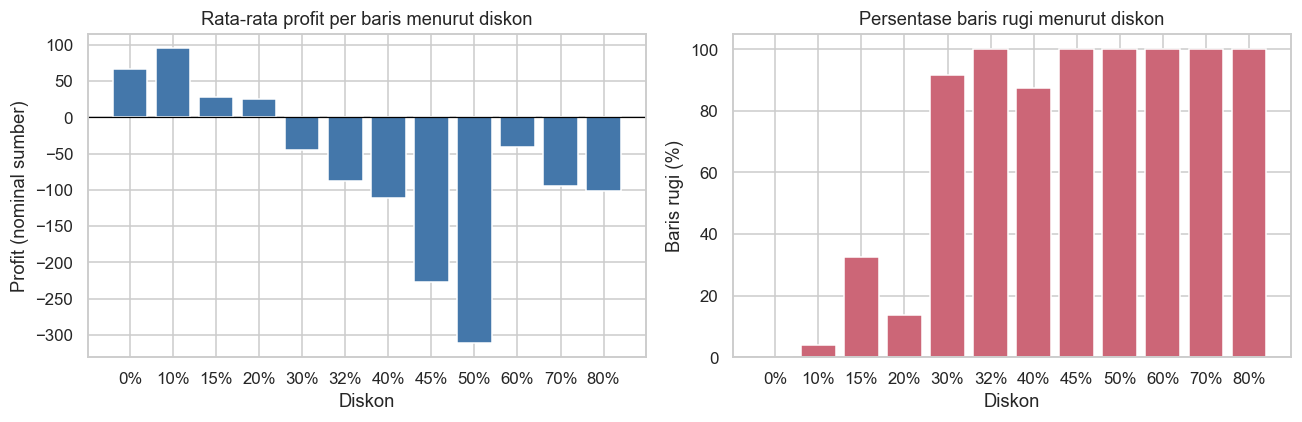

In [19]:
discount_summary = summarize_sales(clean, "discount").sort_index()
discount_summary["rata_rata_profit"] = clean.groupby("discount")["profit"].mean()
display(discount_summary)
display(summarize_sales(clean, ["category", "discount"]).sort_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
discount_labels = [f"{value:.0%}" for value in discount_summary.index]
axes[0].bar(discount_labels, discount_summary["rata_rata_profit"], color="#4477AA")
axes[1].bar(discount_labels, discount_summary["baris_rugi_pct"], color="#CC6677")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(title="Rata-rata profit per baris menurut diskon", xlabel="Diskon", ylabel="Profit (nominal sumber)")
axes[1].set(title="Persentase baris rugi menurut diskon", xlabel="Diskon", ylabel="Baris rugi (%)", ylim=(0, 105))
plt.tight_layout()
plt.show()

### Korelasi antarangka

Korelasi Pearson merangkum hubungan linear pada tingkat baris produk. Nilai mendekati 1 atau -1 menunjukkan hubungan linear yang lebih kuat. Outlier dapat memengaruhinya. ID, kode pos, dan tahun tidak dimasukkan karena angka pada kolom tersebut bukan ukuran transaksi yang sebanding.

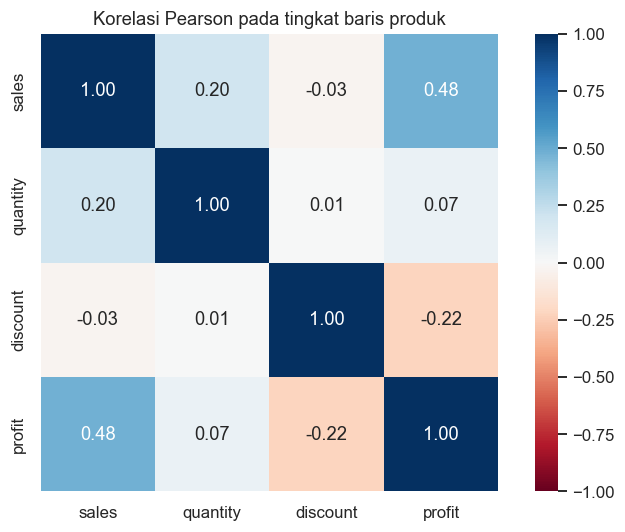

In [20]:
correlation = clean[["sales", "quantity", "discount", "profit"]].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu", center=0,
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Korelasi Pearson pada tingkat baris produk")
plt.tight_layout()
plt.show()

## 16. Berapa lama jeda pesanan sampai dikirim?

Perhitungan ini memakai satu observasi per pesanan agar pesanan dengan banyak produk tidak mendapat bobot lebih besar. Kita membandingkan median, rata-rata, dan rentangnya menurut `ship_mode`.

File tidak memuat tanggal barang diterima atau target layanan. Hasil ini tidak cukup untuk menyebut suatu pengiriman terlambat.

,pesanan,rata_rata_hari,median_hari,minimum_hari,maksimum_hari
ship_mode,,,,,
Same Day,266,0.05,0.00,0,1
First Class,795,2.19,2.00,1,4
Second Class,982,3.23,3.00,1,5
Standard Class,3068,5.00,5.00,3,11


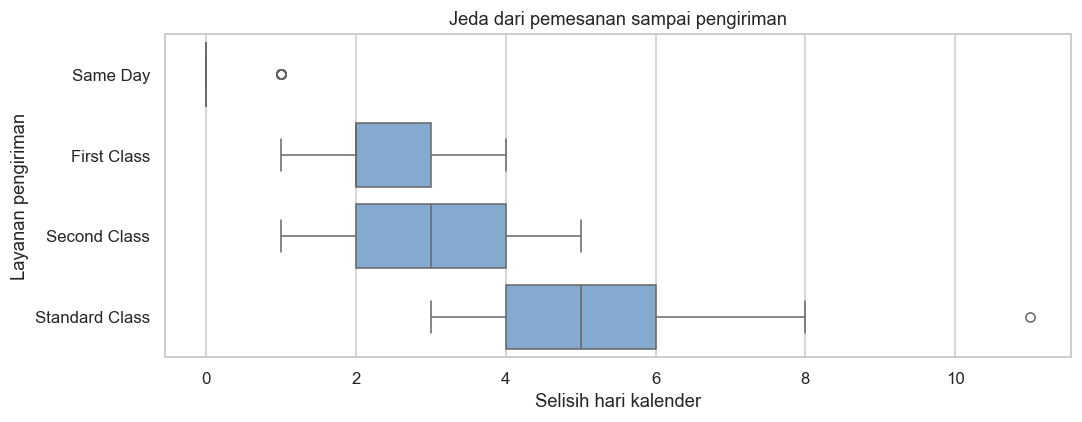

In [21]:
shipping_summary = order_level.groupby("ship_mode").agg(
    pesanan=("order_id", "size"),
    rata_rata_hari=("shipping_days", "mean"),
    median_hari=("shipping_days", "median"),
    minimum_hari=("shipping_days", "min"),
    maksimum_hari=("shipping_days", "max"),
).sort_values("rata_rata_hari")
display(shipping_summary)
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=order_level, x="shipping_days", y="ship_mode",
            order=shipping_summary.index, color="#77AADD", ax=ax)
ax.set(title="Jeda dari pemesanan sampai pengiriman", xlabel="Selisih hari kalender", ylabel="Layanan pengiriman")
plt.tight_layout()
plt.show()

## 17. Seberapa sering pesanan tercatat sebagai retur?

Persentasenya dihitung sebagai **pesanan dengan status retur / seluruh pesanan × 100**. Grafik menggunakan pesanan unik per wilayah, sehingga pesanan berisi banyak produk tetap dihitung satu kali.

Sales dari pesanan yang tercatat retur hanya menunjukkan nilai awal pesanan terkait. Nilai tersebut tidak boleh dianggap sebagai kerugian retur atau nilai refund. Data unit retur, nilai refund, dan tanggal retur tidak tersedia.

,pesanan,pesanan_tercatat_retur,retur_tercatat_pct
region,,,
West,1635,189,11.56
Central,1179,39,3.31
East,1475,44,2.98
South,822,24,2.92


Keseluruhan: 296 dari 5,111 pesanan tercatat retur (5.79%).


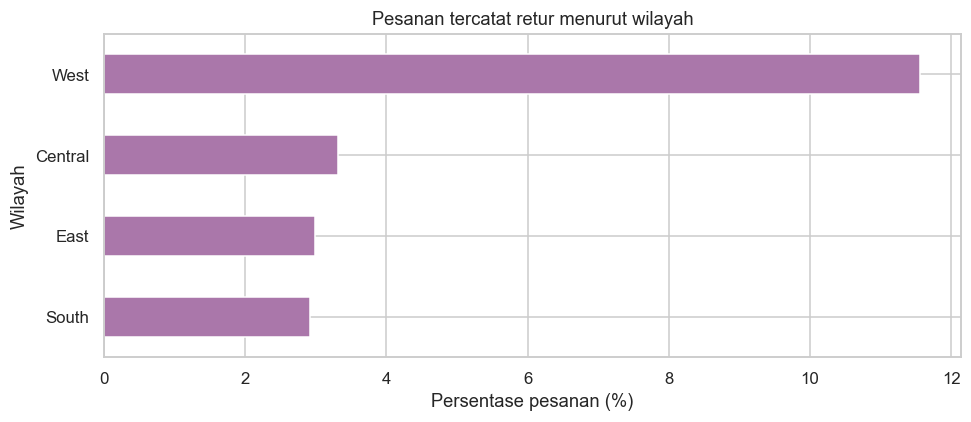

In [22]:
return_summary = order_level.groupby("region").agg(
    pesanan=("order_id", "size"),
    pesanan_tercatat_retur=("is_returned_order", "sum"),
)
return_summary["retur_tercatat_pct"] = (
    return_summary["pesanan_tercatat_retur"] / return_summary["pesanan"] * 100
)
display(return_summary.sort_values("retur_tercatat_pct", ascending=False))
print(f"Keseluruhan: {order_level['is_returned_order'].sum():,} dari {len(order_level):,} pesanan "
      f"tercatat retur ({recorded_return_rate:.2f}%).")

fig, ax = plt.subplots(figsize=(9, 4))
return_summary["retur_tercatat_pct"].sort_values().plot.barh(ax=ax, color="#AA77AA")
ax.set(title="Pesanan tercatat retur menurut wilayah", xlabel="Persentase pesanan (%)", ylabel="Wilayah")
plt.tight_layout()
plt.show()

## 18. Kesimpulan berdasarkan hasil perhitungan

Sel berikut membuat ringkasan dari tabel yang sudah dihitung, sehingga angka dan nama kelompok ikut berubah jika data sumber diperbarui. Tindak lanjutnya merupakan usulan pemeriksaan, bukan hasil uji sebab akibat.

In [23]:
top_sales_category = category_summary["sales"].idxmax()
top_profit_category = category_summary["profit"].idxmax()
worst_subcategory = subcategory_summary["profit"].idxmin()
highest_return_region = return_summary["retur_tercatat_pct"].idxmax()
latest_year = annual.index.max()
latest_growth = annual.loc[latest_year, "pertumbuhan_sales_pct"]

display(Markdown(f"""
- Data hasil cleaning memuat **{len(clean):,} baris produk** dan **{len(order_level):,} pesanan unik**. Total sales sebesar **{total_sales:,.2f}** dan total profit **{total_profit:,.2f}** dalam nominal sumber, dengan margin agregat **{overall_margin:.2f}%**.
- **{top_sales_category}** memiliki total sales tertinggi, sebesar **{category_summary.loc[top_sales_category, 'sales']:,.2f}**. Profit tertinggi berasal dari **{top_profit_category}**, sebesar **{category_summary.loc[top_profit_category, 'profit']:,.2f}**.
- **{worst_subcategory}** memiliki total profit terendah, yaitu **{subcategory_summary.loc[worst_subcategory, 'profit']:,.2f}**. Tinjau transaksi, diskon, dan komposisi produk pada kelompok ini sebelum mengubah kebijakan harga.
- Sales pada **{latest_year}** berubah **{latest_growth:.2f}%** dibanding tahun sebelumnya. Bandingkan juga cakupan tanggal dan bulan dalam tabel tahunan.
- Ada **{order_level['is_returned_order'].sum():,} pesanan** yang tercatat retur, setara **{recorded_return_rate:.2f}%** dari seluruh pesanan. **{highest_return_region}** memiliki persentase tertinggi pada tabel wilayah. Periksa volume serta kelengkapan pencatatan sebelum membandingkan proses retur.
- Ada **{len(conflicting_order_ids)} pesanan** dengan konflik ID pelanggan dan **{len(similar_transactions)} baris** dalam kelompok transaksi mirip. Konfirmasi ke pemilik data sebelum analisis pelanggan atau penghapusan baris lebih lanjut.
"""))


- Data hasil cleaning memuat **10,194 baris produk** dan **5,111 pesanan unik**. Total sales sebesar **2,326,534.35** dan total profit **292,296.81** dalam nominal sumber, dengan margin agregat **12.56%**.
- **Technology** memiliki total sales tertinggi, sebesar **839,893.28**. Profit tertinggi berasal dari **Technology**, sebesar **146,543.38**.
- **Tables** memiliki total profit terendah, yaitu **-17,753.21**. Tinjau transaksi, diskon, dan komposisi produk pada kelompok ini sebelum mengubah kebijakan harga.
- Sales pada **2024** berubah **21.44%** dibanding tahun sebelumnya. Bandingkan juga cakupan tanggal dan bulan dalam tabel tahunan.
- Ada **296 pesanan** yang tercatat retur, setara **5.79%** dari seluruh pesanan. **West** memiliki persentase tertinggi pada tabel wilayah. Periksa volume serta kelengkapan pencatatan sebelum membandingkan proses retur.
- Ada **2 pesanan** dengan konflik ID pelanggan dan **4 baris** dalam kelompok transaksi mirip. Konfirmasi ke pemilik data sebelum analisis pelanggan atau penghapusan baris lebih lanjut.


### Batas penggunaan hasil

Agregasi nominal lintas negara bergantung pada asumsi kesetaraan satuan yang dijelaskan di awal. Data ini belum menjelaskan kurs, biaya rinci, alasan retur, atau penyebab perubahan penjualan. Analisis diskon dan korelasi memberi petunjuk untuk pemeriksaan berikutnya.

Untuk pembahasan lanjutan, pilih satu pertanyaan lalu dukung jawaban dengan angka dan grafik:

1. Apakah subkategori dengan sales tertinggi juga memiliki margin tertinggi?
2. Pada kategori Furniture, bagaimana persentase baris rugi berubah menurut diskon?
3. Bagaimana perbandingan margin wilayah jika hanya memakai data United States?
4. Berapa perubahan total sales jika transaksi mirip dihapus? Mengapa penghapusan itu masih memerlukan konfirmasi?
5. Apakah kesimpulan tentang diskon tetap sama ketika produk dan wilayah dibandingkan dalam kelompok yang serupa?

## 19. Menyimpan hasil dan memeriksa ulang

Data bersih disimpan sebagai CSV, bersama ringkasan dan catatan audit. CSV mudah dibuka kembali di Python. Saat membukanya melalui Excel, impor kolom kode pos sebagai teks agar nol di depan tetap tersimpan. Untuk membacanya kembali dengan pandas, gunakan `dtype={"postal_code": "string"}`.

Menjalankan ulang sel ini akan memperbarui file hasil dengan nama yang sama di `output_superstore`. Pemeriksaan terakhir membandingkan jumlah baris, identitas baris, serta total sales dan profit setelah file dibaca kembali.

In [24]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
exports = {
    "superstore_clean.csv": clean,
    "superstore_order_level.csv": order_level,
    "cleaning_log.csv": cleaning_log,
    "quality_profile.csv": quality_profile.reset_index(names="kolom"),
    "customer_conflicts.csv": customer_conflicts,
    "similar_transactions.csv": similar_transactions,
    "unmatched_returns.csv": unmatched_returns,
    "outlier_audit.csv": outlier_audit,
    "category_summary.csv": category_summary.reset_index(),
    "monthly_summary.csv": monthly.reset_index(),
    "return_summary.csv": return_summary.reset_index(),
}
for filename, table in exports.items():
    table.to_csv(OUTPUT_DIR / filename, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")

reloaded = pd.read_csv(
    OUTPUT_DIR / "superstore_clean.csv",
    dtype={"postal_code": "string"},
    parse_dates=["order_date", "ship_date", "order_month"],
)
assert len(reloaded) == len(clean)
assert reloaded["row_id"].tolist() == clean["row_id"].tolist()
assert reloaded["postal_code"].tolist() == clean["postal_code"].tolist()
np.testing.assert_allclose(reloaded[["sales", "profit"]].sum(), clean[["sales", "profit"]].sum())

# Memastikan tabel sumber di memori juga tidak berubah selama cleaning.
pd.testing.assert_frame_equal(orders_raw, raw_sheets["Orders"])
print("Pemeriksaan ekspor selesai: jumlah baris, Row ID, kode pos, sales, dan profit sesuai.")
display(pd.DataFrame({"file": list(exports),
                      "baris": [len(table) for table in exports.values()]}))
print("Folder hasil:", OUTPUT_DIR)

Pemeriksaan ekspor selesai: jumlah baris, Row ID, kode pos, sales, dan profit sesuai.


,file,baris
0,superstore_clean.csv,10194
1,superstore_order_level.csv,5111
2,cleaning_log.csv,7
3,quality_profile.csv,21
4,customer_conflicts.csv,8
5,similar_transactions.csv,4
6,unmatched_returns.csv,0
7,outlier_audit.csv,2
8,category_summary.csv,3
9,monthly_summary.csv,48


Folder hasil: F:\programming\ngajar\full_stack_bangalore\Sesi 4-5 - Python (EDA & Cleaning)\output_superstore
